# HNSW visualization

This notebook builds a small HNSW graph on **2-D points** so the layers can actually be drawn.
It shows:

1. how many nodes end up on each layer (random level assignment)
2. the graph on every layer
3. the path a search takes: greedy descent on the upper layers, then beam search on layer 0
4. how `ef_search` changes the number of nodes visited and the recall

Everything uses `vecsearch.HNSWIndex` from this project (no external ANN library).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from vecsearch import HNSWIndex, BruteForceIndex

# colours used in all plots
NODE, EDGE, PATH, RESULT, QUERY = "#2a78d6", "#c9c8c3", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Build the index

300 random points in the unit square. `M=4` is much smaller than normal (16), which gives
more layers (`mL = 1/ln(M)`) and a sparse graph that is easy to look at.

In [2]:
rng = np.random.default_rng(7)
points = rng.random((300, 2)).astype(np.float32)

index = HNSWIndex(dim=2, M=4, ef_construction=40, ef_search=10, seed=8)
index.add(points)

stats = index.graph_stats()
print("max level:", stats["max_level"], " entry point:", index.entry_point)
for s in stats["layers"]:
    print(f"layer {s['layer']}: {s['nodes']:4d} nodes, avg out-degree {s['avg_degree']:.2f}")

max level: 4  entry point: 156
layer 0:  300 nodes, avg out-degree 6.39
layer 1:   69 nodes, avg out-degree 4.00
layer 2:   17 nodes, avg out-degree 4.00
layer 3:    5 nodes, avg out-degree 4.00
layer 4:    2 nodes, avg out-degree 1.00


## 2. Level distribution

Each node gets level `floor(-ln(U) * mL)` with `U ~ Uniform(0,1)` and `mL = 1/ln(M)`.
So `P(level >= l) = M^(-l)`: every layer has about `1/M` of the nodes of the layer below,
exactly like a skip list. Below: the observed node count per layer vs. the expected `n / M^l`.

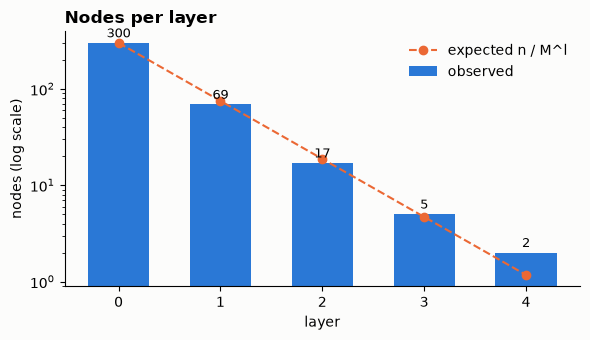

In [3]:
layers = np.arange(index.max_level + 1)
observed = [len(index.layer_nodes(l)) for l in layers]
expected = [len(points) / index.M ** l for l in layers]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(layers, observed, color=NODE, width=0.6, label="observed")
ax.plot(layers, expected, "o--", color=PATH, label="expected n / M^l")
for l, v in zip(layers, observed):
    ax.annotate(str(v), (l, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax.set_yscale("log"); ax.set_xticks(layers)
ax.set_xlabel("layer"); ax.set_ylabel("nodes (log scale)")
ax.set_title("Nodes per layer", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. The graph on every layer

Top layers are tiny "express lanes" with long edges; layer 0 contains every point with short local edges.

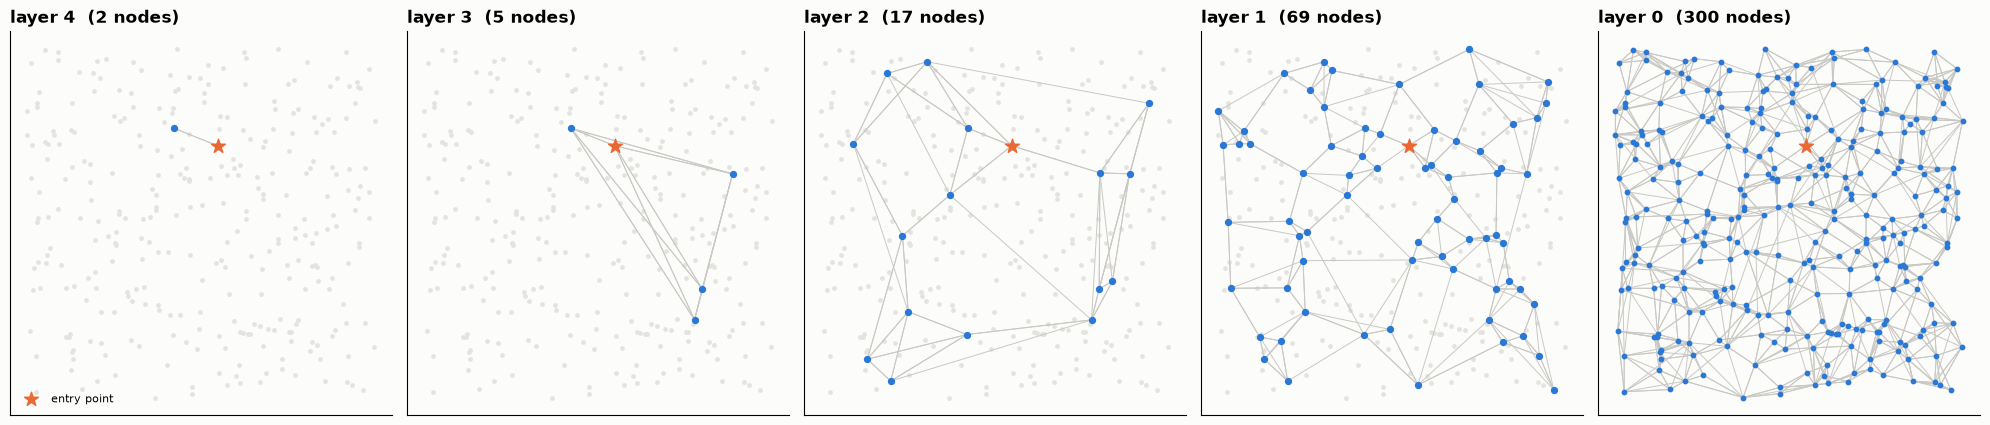

In [4]:
def draw_layer(ax, layer, title=True):
    for u, v in index.layer_edges(layer):
        ax.plot(*zip(points[u], points[v]), color=EDGE, lw=0.7, zorder=1)
    ax.scatter(points[:, 0], points[:, 1], s=6, color="#e4e3df", zorder=0)   # all points, faded
    nodes = index.layer_nodes(layer)
    ax.scatter(points[nodes, 0], points[nodes, 1], s=18 if layer else 10, color=NODE, zorder=2)
    ep = index.entry_point
    if ep in nodes:
        ax.scatter(*points[ep], s=110, marker="*", color=PATH, zorder=3, label="entry point")
    if title:
        ax.set_title(f"layer {layer}  ({len(nodes)} nodes)", loc="left", fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")

n_layers = index.max_level + 1
fig, axes = plt.subplots(1, n_layers, figsize=(4 * n_layers, 4.2))
axes = np.atleast_1d(axes)
for l, ax in zip(range(index.max_level, -1, -1), axes):
    draw_layer(ax, l)
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Search path for one query

* **orange line**: greedy descent. On each upper layer we keep jumping to the neighbour
  closest to the query until no neighbour is closer, then drop down one layer.
* **blue rings (layer 0)**: nodes expanded by the beam search (popped from the candidate MinHeap).
* **green**: the final k=5 results.

greedy path (layer, node): [(4, 156), (3, 156), (3, 1), (2, 1), (1, 1), (1, 285), (0, 285)]
nodes expanded on layer 0: 10
results: [285, 19, 58, 184, 289]


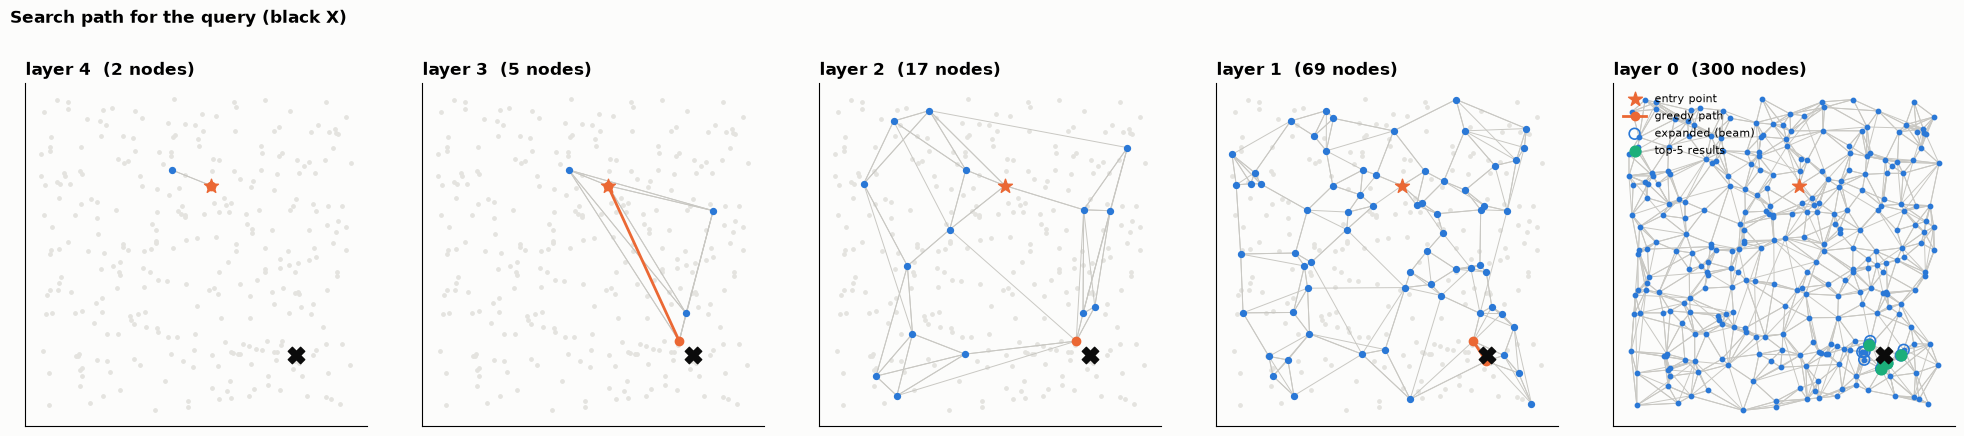

In [5]:
query = np.array([0.82, 0.18], dtype=np.float32)
trace = index.search_with_trace(query, k=5, ef=10)

print("greedy path (layer, node):", trace["path"])
print("nodes expanded on layer 0:", len(trace["expanded"]))
print("results:", trace["ids"].tolist())

fig, axes = plt.subplots(1, n_layers, figsize=(4 * n_layers, 4.4))
axes = np.atleast_1d(axes)
for l, ax in zip(range(index.max_level, -1, -1), axes):
    draw_layer(ax, l)
    hops = [n for (lay, n) in trace["path"] if lay == l]
    if hops:
        xy = points[hops]
        ax.plot(xy[:, 0], xy[:, 1], "-o", color=PATH, lw=2, ms=6, zorder=4, label="greedy path")
    if l == 0:
        exp = points[trace["expanded"]]
        ax.scatter(exp[:, 0], exp[:, 1], s=60, facecolors="none", edgecolors=NODE, lw=1.2, zorder=4,
                   label="expanded (beam)")
        res = points[trace["ids"]]
        ax.scatter(res[:, 0], res[:, 1], s=60, color=RESULT, zorder=5, label="top-5 results")
        ax.legend(loc="upper left", frameon=False, fontsize=8)
    ax.scatter(*query, s=140, marker="X", color=QUERY, zorder=6)
plt.suptitle("Search path for the query (black X)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

## 5. Effect of `ef_search`

`ef` is the size of the result MaxHeap during the layer-0 beam search. A bigger beam explores more
nodes, so recall goes up and so does the work.

In 2-D the graph is so easy to navigate that recall is already 1.0 at the smallest beam, so this part
uses **3,000 random points in 16 dimensions** with a small `M=6`, where the trade-off is clearly visible.
We measure recall and the number of expanded nodes on 200 random queries.

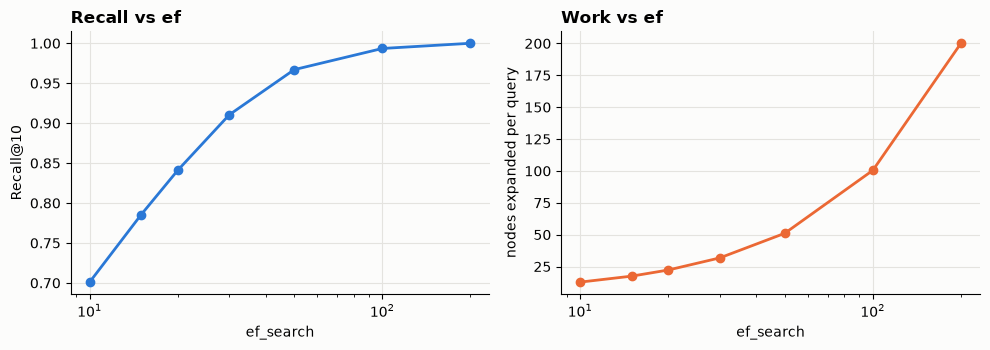

ef=  10  recall=0.701  expanded=  12.8
ef=  15  recall=0.785  expanded=  17.5
ef=  20  recall=0.841  expanded=  22.3
ef=  30  recall=0.910  expanded=  31.8
ef=  50  recall=0.967  expanded=  51.1
ef= 100  recall=0.994  expanded= 100.5
ef= 200  recall=1.000  expanded= 200.1


In [6]:
data16 = rng.random((3000, 16)).astype(np.float32)
index16 = HNSWIndex(dim=16, M=6, ef_construction=50, seed=1)
index16.add(data16)
exact = BruteForceIndex(16); exact.add(data16)
queries = rng.random((200, 16)).astype(np.float32)
k = 10
efs = [10, 15, 20, 30, 50, 100, 200]   # ef is always at least k
recalls, visited = [], []
for ef in efs:
    hits, vis = 0, 0
    for q in queries:
        t = index16.search_with_trace(q, k=k, ef=ef)
        truth = set(exact.search(q, k)[0].tolist())
        hits += len(truth & set(t["ids"].tolist()))
        vis += len(t["expanded"])
    recalls.append(hits / (k * len(queries)))
    visited.append(vis / len(queries))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(efs, recalls, "-o", color=NODE, lw=2)
axes[0].set_xscale("log"); axes[0].set_xlabel("ef_search"); axes[0].set_ylabel(f"Recall@{k}")
axes[0].set_title("Recall vs ef", loc="left", fontweight="bold")
axes[1].plot(efs, visited, "-o", color=PATH, lw=2)
axes[1].set_xscale("log"); axes[1].set_xlabel("ef_search"); axes[1].set_ylabel("nodes expanded per query")
axes[1].set_title("Work vs ef", loc="left", fontweight="bold")
for ax in axes: ax.grid(color="#e4e3df")
plt.tight_layout(); plt.show()
for ef, r, v in zip(efs, recalls, visited):
    print(f"ef={ef:4d}  recall={r:.3f}  expanded={v:6.1f}")

## Observations

* Layer sizes drop by roughly a factor of M per level, as predicted by the level formula.
* The upper layers have long edges, so the greedy descent crosses the whole square in a few hops.
  Most of the work happens on layer 0.
* `ef` can't be smaller than `k` (the beam must hold k results). In 16-D, recall climbs towards 1.0 as
  `ef` grows past `k`, while the number of expanded nodes keeps growing roughly linearly with `ef`, so
  the last bits of recall are the most expensive. This is the main speed/accuracy knob of HNSW, and it
  can be changed per query without rebuilding the graph.